In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

print("Libraries imported successfully!")

Libraries imported successfully!


In [15]:
file_path = Path(
    r"C:\Users\Sarthak\OneDrive\Desktop\ChurnGuard AI\data\Telco_customer_churn.xlsx"
)

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [16]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   i

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,7043,7043,3668-QPYBK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
Lat Long,7043,1652,"33.964131, -118.272783",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
print("Missing values per column:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
      .query("`Missing Values` > 0")
)

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:


,Missing Values
Churn Reason,5174



Duplicate rows: 0


Churn counts:
Churn Value
0    5174
1    1869
Name: count, dtype: int64

Churn percentages:
Churn Value
0    73.46
1    26.54
Name: proportion, dtype: float64


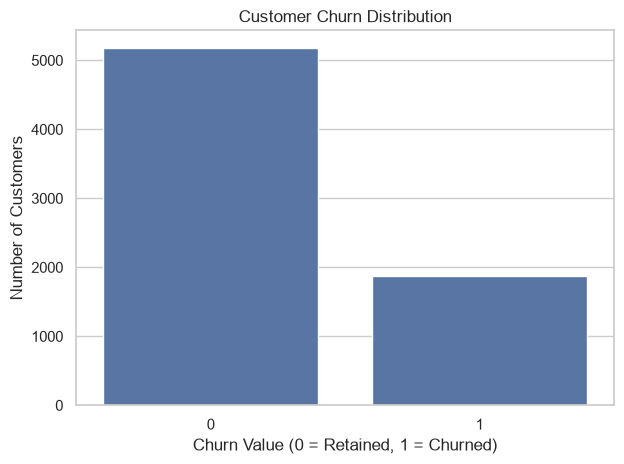

In [18]:
target_col = "Churn Value"

print("Churn counts:")
print(df[target_col].value_counts(dropna=False).sort_index())

print("\nChurn percentages:")
print(
    (df[target_col].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

sns.countplot(data=df, x=target_col)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Value (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

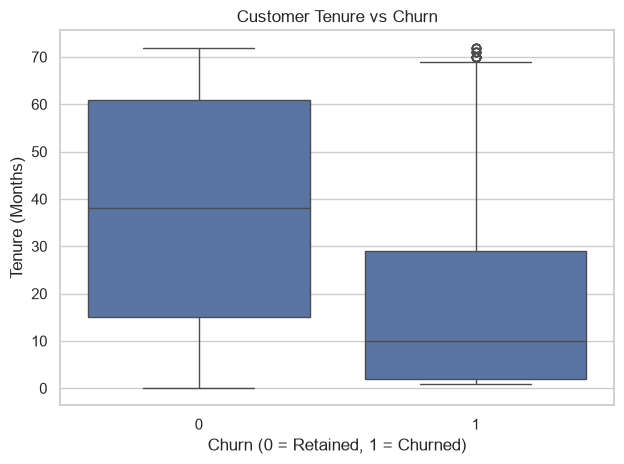

,mean,median,min,max
Churn Value,,,,
0,37.569965,38.0,0,72
1,17.979133,10.0,1,72


In [19]:
tenure_col = next(
    (c for c in ["Tenure Months", "Tenure in Months", "Tenure"] if c in df.columns),
    None
)

if tenure_col is None:
    print("Tenure column not found. Check df.columns.tolist().")
else:
    sns.boxplot(data=df, x=target_col, y=tenure_col)

    plt.title("Customer Tenure vs Churn")
    plt.xlabel("Churn (0 = Retained, 1 = Churned)")
    plt.ylabel("Tenure (Months)")
    plt.tight_layout()
    plt.show()

    display(df.groupby(target_col)[tenure_col].agg(["mean", "median", "min", "max"]))

Churn percentage by contract:


Churn Value,0,1
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


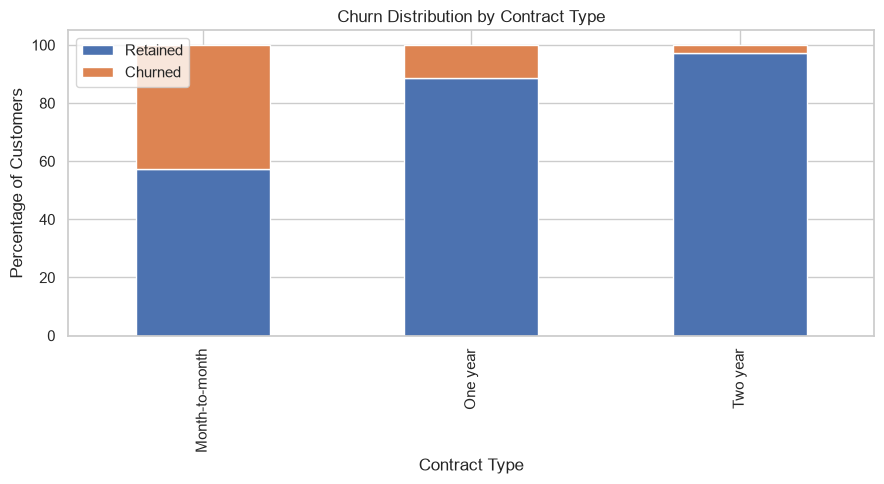

In [20]:
contract_col = next(
    (c for c in ["Contract"] if c in df.columns),
    None
)

if contract_col:
    churn_by_contract = pd.crosstab(
        df[contract_col],
        df[target_col],
        normalize="index"
    ) * 100

    print("Churn percentage by contract:")
    display(churn_by_contract.round(2))

    churn_by_contract.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    plt.title("Churn Distribution by Contract Type")
    plt.xlabel("Contract Type")
    plt.ylabel("Percentage of Customers")
    plt.legend(["Retained", "Churned"])
    plt.tight_layout()
    plt.show()

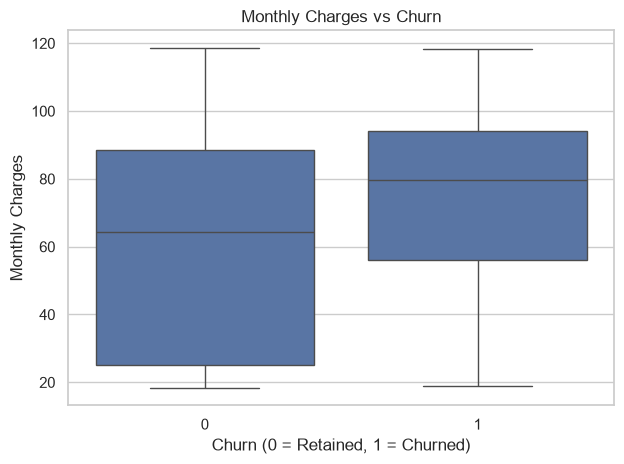

,mean,median
Churn Value,,
0,61.265124,64.425
1,74.441332,79.650


In [21]:
monthly_col = next(
    (c for c in ["Monthly Charges", "Monthly Charge"] if c in df.columns),
    None
)

if monthly_col:
    sns.boxplot(data=df, x=target_col, y=monthly_col)

    plt.title("Monthly Charges vs Churn")
    plt.xlabel("Churn (0 = Retained, 1 = Churned)")
    plt.ylabel("Monthly Charges")
    plt.tight_layout()
    plt.show()

    display(df.groupby(target_col)[monthly_col].agg(["mean", "median"]))
else:
    print("Monthly charges column not found. Inspect your column names.")

In [22]:
total_col = next(
    (c for c in ["Total Charges", "TotalCharges"] if c in df.columns),
    None
)

if total_col:
    df[total_col] = pd.to_numeric(df[total_col], errors="coerce")

    print("Converted column:", total_col)
    print("Missing values after conversion:", df[total_col].isna().sum())
else:
    print("Total charges column not found. Check the column names.")

Converted column: Total Charges
Missing values after conversion: 11


In [23]:
# Separate the target variable
y = pd.to_numeric(df[target_col], errors="coerce")

# Columns that must not be used as model inputs
excluded_keywords = [
    "churn score",
    "churn label",
    "churn reason",
    "customer status",
    "customerid",
    "customer id",
    "customer_id",
    "cltv"
]

excluded_cols = [
    col for col in df.columns
    if col == target_col
    or any(keyword in col.lower().strip() for keyword in excluded_keywords)
]

X = df.drop(columns=excluded_cols).copy()

# Remove rows with missing target labels, if any
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

print("Excluded columns:")
print(excluded_cols)

print("\nFeatures remaining:", X.shape[1])
print("Target records:", len(y))
print("\nTarget distribution:")
print(y.value_counts())

Excluded columns:
['CustomerID', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Features remaining: 27
Target records: 7043

Target distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64


In [24]:
# Remove geographic coordinates and customer identifiers if present.
# These are excluded from the initial model to keep the feature set manageable.

identifier_cols = [
    c for c in X.columns
    if c.lower().strip() in [
        "customerid", "customer id", "customer_id",
        "latitude", "longitude", "zip code", "zipcode"
    ]
]

X = X.drop(columns=identifier_cols, errors="ignore")

# Remove columns that have only one unique value
constant_cols = [
    c for c in X.columns
    if X[c].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_cols, errors="ignore")

print("Removed identifier columns:", identifier_cols)
print("Removed constant columns:", constant_cols)

print("\nFinal feature matrix shape:", X.shape)
display(X.head())

Removed identifier columns: ['Zip Code', 'Latitude', 'Longitude']
Removed constant columns: ['Count', 'Country', 'State']

Final feature matrix shape: (7043, 21)


,City,Lat Long,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Los Angeles,"33.964131, -118.272783",Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
1,Los Angeles,"34.059281, -118.30742",Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
2,Los Angeles,"34.048013, -118.293953",Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50
3,Los Angeles,"34.062125, -118.315709",Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05
4,Los Angeles,"34.039224, -118.266293",Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30


In [25]:
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")

        # Convert only when the non-missing values are genuinely numeric.
        original_nonmissing = X[col].notna().sum()

        if original_nonmissing > 0:
            conversion_ratio = converted.notna().sum() / original_nonmissing

            if conversion_ratio >= 0.95:
                X[col] = converted

print("Updated feature data types:")
print(X.dtypes)

Updated feature data types:
City                     str
Lat Long                 str
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges        float64
dtype: object


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining churn proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 5634
Testing records: 1409

Training churn proportions:
Churn Value
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing churn proportions:
Churn Value
0    0.735
1    0.265
Name: proportion, dtype: float64


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical features: ['City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


C:\Users\Sarthak\AppData\Local\Temp\ipykernel_10544\3206296245.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [28]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("ML models and evaluation metrics imported.")

ML models and evaluation metrics imported.


In [30]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )
    for name, model in models.items()
}

print("Created", len(pipelines), "model pipelines.")

Created 3 model pipelines.


In [31]:
for name, pipeline in pipelines.items():
    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    print(f"{name} training completed.\n")

Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training Random Forest...
Random Forest training completed.



In [32]:
results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7864,0.6137,0.5267,0.5669,0.8337
Decision Tree,0.7417,0.5087,0.7781,0.6152,0.8272
Random Forest,0.7502,0.5195,0.7834,0.6247,0.8378


In [33]:
for name, pipeline in pipelines.items():
    print("=" * 60)
    print(name)
    print("=" * 60)

    y_pred = pipeline.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Retained", "Churned"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    Retained       0.84      0.88      0.86      1035
     Churned       0.61      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

Decision Tree
              precision    recall  f1-score   support

    Retained       0.90      0.73      0.81      1035
     Churned       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409

Random Forest
              precision    recall  f1-score   support

    Retained       0.90      0.74      0.81      1035
     Churned       0.52      0.78      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80   

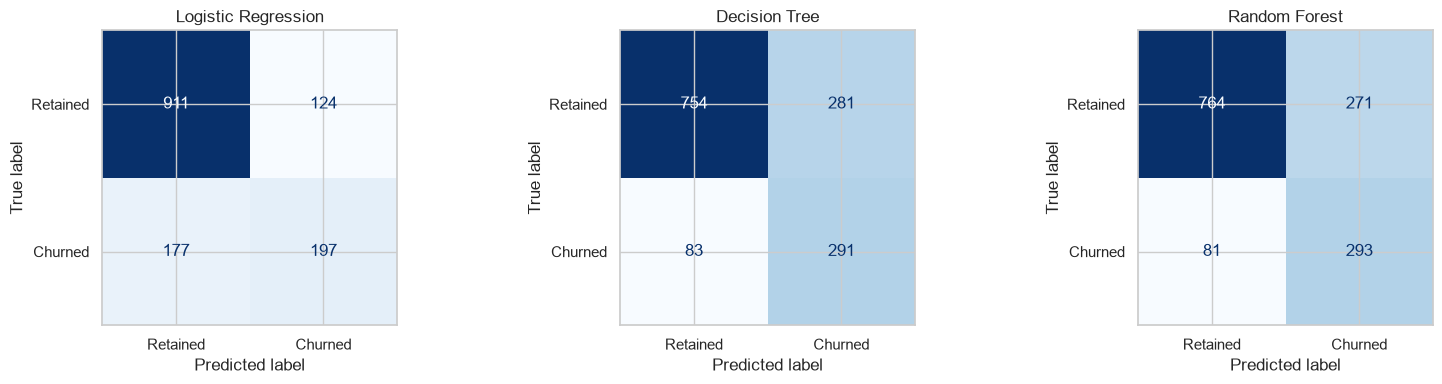

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, pipeline) in zip(axes, pipelines.items()):
    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Retained", "Churned"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

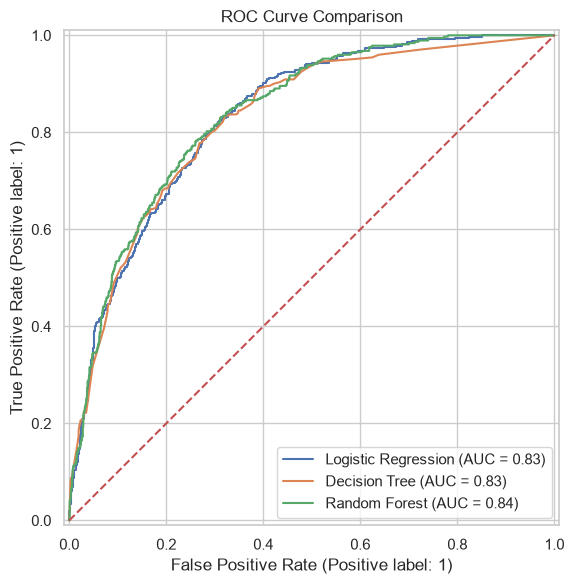

In [35]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, pipeline in pipelines.items():
    RocCurveDisplay.from_estimator(
        pipeline,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

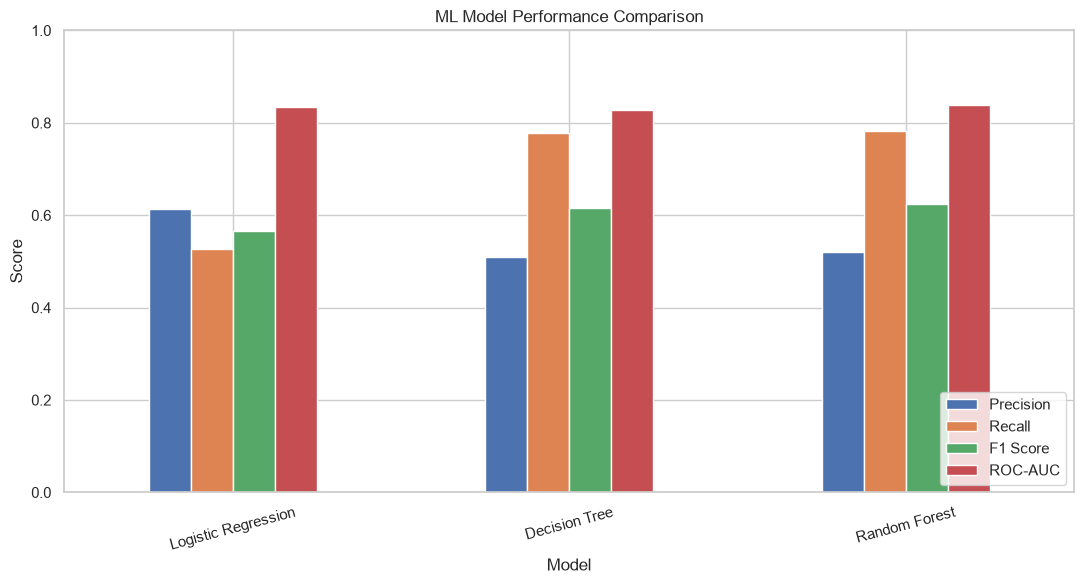

In [36]:
results_df[
    ["Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("ML Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [37]:
rf_pipeline = pipelines["Random Forest"]

fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
fitted_rf = rf_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

,Feature,Importance
2815,cat__Contract_Month-to-month,0.093366
2817,cat__Contract_Two year,0.062122
0,num__Tenure Months,0.058146
2,num__Total Charges,0.050616
2795,cat__Internet Service_Fiber optic,0.046182
2797,cat__Online Security_No,0.044874
2787,cat__Dependents_No,0.044234
2822,cat__Payment Method_Electronic check,0.042411
2806,cat__Tech Support_No,0.038957
2788,cat__Dependents_Yes,0.034707


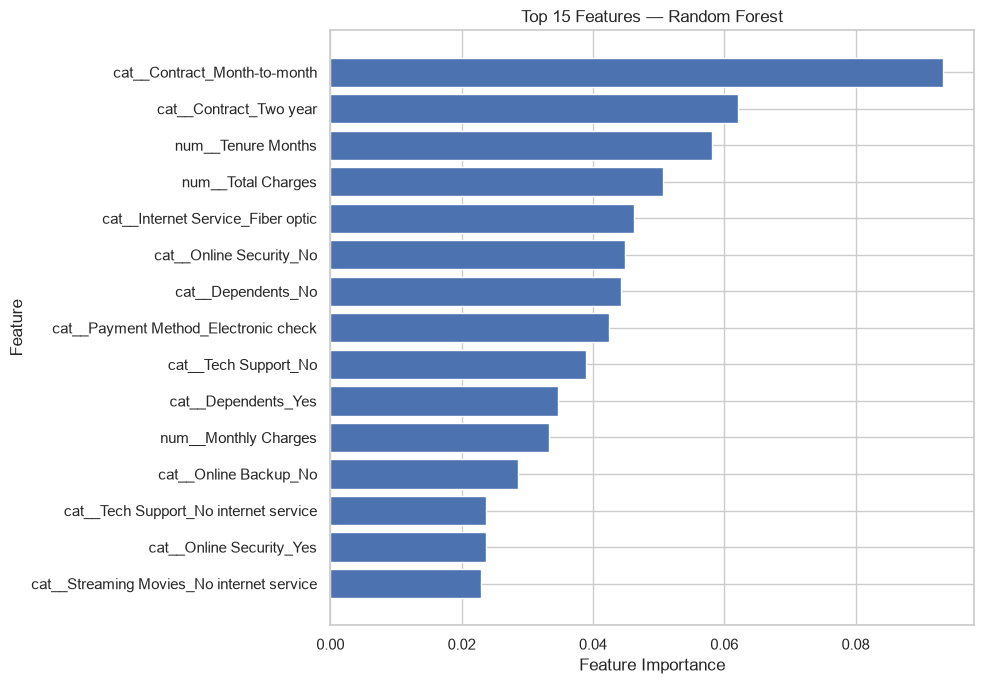

In [38]:
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [39]:
import joblib
from pathlib import Path

project_dir = Path(
    r"C:\Users\Sarthak\OneDrive\Desktop\ChurnGuard AI"
)

models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

best_model_name = results_df["F1 Score"].idxmax()
best_pipeline = pipelines[best_model_name]

model_path = models_dir / "churn_model.joblib"

joblib.dump(best_pipeline, model_path)

print("Selected model:", best_model_name)
print("Saved model to:", model_path)

Selected model: Random Forest
Saved model to: C:\Users\Sarthak\OneDrive\Desktop\ChurnGuard AI\models\churn_model.joblib


In [40]:
# Select one customer from the test set
sample_customer = X_test.iloc[[0]]

actual_value = int(y_test.iloc[0])

predicted_value = int(best_pipeline.predict(sample_customer)[0])
predicted_probability = float(
    best_pipeline.predict_proba(sample_customer)[0, 1]
)

print("Actual churn value:", actual_value)
print("Predicted churn value:", predicted_value)
print(
    f"Predicted churn probability: {predicted_probability:.2%}"
)

Actual churn value: 0
Predicted churn value: 0
Predicted churn probability: 24.87%


In [41]:
results_path = project_dir / "model_comparison.csv"

results_df.to_csv(results_path)

print("Evaluation results saved to:", results_path)

Evaluation results saved to: C:\Users\Sarthak\OneDrive\Desktop\ChurnGuard AI\model_comparison.csv


In [45]:
print("Number of features:", len(X.columns))
print(X.columns.tolist())

Number of features: 21
['City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']


In [46]:
print(X.dtypes)

City                     str
Lat Long                 str
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges        float64
dtype: object
